# 01 Data: what is in our WikiArt subset?

**Goal of this notebook.** Before we train anything, we look at the data. We want to know:

1. how many images we have per style, and who painted them;
2. how we split them into **train** (to learn), **validation** (to choose settings) and **test**
   (to measure once, at the very end);
3. whether simple things like colour already separate the styles (if yes, a classical model may
   be enough for the museum);
4. whether some images are near copies of each other (a copy in train and in test would make the
   test too easy).

**About the paintings.** The WikiArt images keep their authors' rights. This notebook does not
show them in the version stored on GitHub. To see them on your own computer, run it with the
environment variable `SHOW_ARTWORKS=1`: the image grids are then saved to `reports/private/`,
a folder that Git ignores.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from museum_guide.config import PRIVATE_DIR, REPORTS_DIR, SHOW_ARTWORKS, set_seed
from museum_guide.data import UNKNOWN_ARTIST, class_names, load_images, load_metadata, make_split
from museum_guide.evaluation import save_results
from museum_guide.plots import CLASS_COLORS, save_figure

set_seed()
pd.set_option("display.width", 120)

## 1. The images

**What we do.** We read `metadata.csv`, written by the download script: one row per image with
its style (our label), its genre, its painter and its original size.

In [2]:
meta = load_metadata()
classes = class_names(meta)
print(len(meta), "images,", len(classes), "classes:", classes)
meta.groupby("label").size().rename("images").to_frame()

1500 images, 5 classes: ['Baroque', 'Cubism', 'Impressionism', 'Pop_Art', 'Ukiyo_e']


,images
label,
Baroque,300
Cubism,300
Impressionism,300
Pop_Art,300
Ukiyo_e,300


In [3]:
sizes = meta[["orig_width", "orig_height"]]
print("original size in pixels (before the download script cut a 224 x 224 square):")
sizes.describe().loc[["min", "50%", "max"]].round(0)

original size in pixels (before the download script cut a 224 x 224 square):


,orig_width,orig_height
min,1381.0,1381.0
50%,1382.0,1502.0
max,6273.0,7500.0


**What we see.** We have 1 500 images, exactly 300 per style: the classes are **balanced**. A model
that always gives the same answer is right 20 % of the time. This is our **chance level**: any
useful model must do much better than 20 %.

The original scans are big (at least 1 381 pixels on each side). The download script kept the
central square of each painting and shrank it to 224 x 224 pixels, so the borders are cut.

## 2. Who painted them?

**What we do.** We count, for each style, how many images have a **known painter** and how many
are labelled "Unknown Artist" (WikiArt uses this label for every painter outside its list of 129
names, so it mixes many different people).

Why it matters: if the same painter is in the training set and in the test set, the model can
recognise the **painter** (their colours, their favourite subjects) instead of the **style**. The test
score would then look better than what the museum will get with new paintings.

In [4]:
known = meta["artist"] != UNKNOWN_ARTIST
painters = meta.assign(known=known).groupby("label").agg(
    images=("id", "size"),
    known_painter=("known", "sum"),
    painters=("artist", lambda a: a[a != UNKNOWN_ARTIST].nunique()),
)
painters["share_known"] = (painters["known_painter"] / painters["images"]).round(2)
painters

,images,known_painter,painters,share_known
label,,,,
Baroque,300,88,9,0.29
Cubism,300,155,12,0.52
Impressionism,300,300,11,1.00
Pop_Art,300,14,1,0.05
Ukiyo_e,300,61,2,0.20


In [5]:
top = meta[known].groupby(["label", "artist"]).size().rename("images")
top.sort_values(ascending=False).groupby(level=0).head(3).sort_index().to_frame()

images
label         artist                       
Baroque       frans-hals                  8
              peter-paul-rubens           9
              rembrandt                  50
Cubism        pablo-picasso              47
              paul-cezanne               32
              pyotr-konchalovsky         25
Impressionism camille-pissarro           50
              claude-monet               50
              pierre-auguste-renoir      50
Pop_Art       andy-warhol                14
Ukiyo_e       katsushika-hokusai         32
              utagawa-kuniyoshi          29

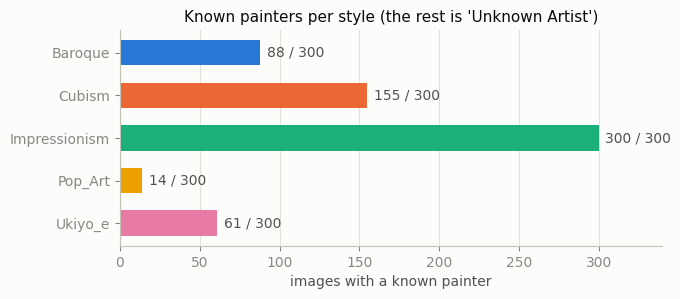

In [6]:
fig, ax = plt.subplots(figsize=(7, 2.8))
y = np.arange(len(classes))
ax.barh(y, painters["known_painter"], color=[CLASS_COLORS[c] for c in classes], height=0.6)
for yi, (n, total) in enumerate(zip(painters["known_painter"], painters["images"])):
    ax.text(n + 4, yi, f"{n} / {total}", va="center", color="#52514e")
ax.set_yticks(y, classes)
ax.invert_yaxis()
ax.set_xlim(0, 340)
ax.set_xlabel("images with a known painter")
ax.set_title("Known painters per style (the rest is 'Unknown Artist')")
ax.grid(axis="y", visible=False)
save_figure(fig, "01_known_painters")
plt.show()

**What we see.** The styles are very different on this point:

- All 300 **Impressionist** images come from 11 known painters. Monet, Renoir and Pissarro give 50
  images each: this is the maximum we allowed per painter.
- **Pop Art** is the opposite. Only 14 images have a known painter (Andy Warhol); the other 286 are
  "Unknown Artist".

Thanks to the 50-image cap, no single painter can fill a whole style. But for the 882 images by
"Unknown Artist" (59 % of the data) we cannot check who painted them. This is a **limit of the
data**, and we keep it in mind when we read the scores.

## 3. Train, validation and test

**What we do.** We cut the 1 500 images into three parts:

- **train** (about 70 %): the model learns from these images;
- **validation** (about 15 %): we use it to compare models and choose settings;
- **test** (about 15 %): we look at it **once**, at the very end, to report the final score.

The split is **stratified** (each part has about the same number of images of each style) and
**grouped by painter**: all the images of a known painter go to the same part. We compare it with
a plain random split, which ignores painters.

In [7]:
meta["split"] = make_split(meta, by_artist=True)
pd.crosstab(meta["label"], meta["split"], margins=True)[["train", "val", "test", "All"]]

split,train,val,test,All
label,,,,
Baroque,216,42,42,300
Cubism,216,42,42,300
Impressionism,200,50,50,300
Pop_Art,214,43,43,300
Ukiyo_e,215,42,43,300
All,1061,219,220,1500


In [8]:
def painters_in_several_parts(split):
    """Number of known painters whose images end up in more than one part."""
    named = meta.assign(part=split)[known]
    return int((named.groupby("artist")["part"].nunique() > 1).sum())


random_split = make_split(meta, by_artist=False)
leak = {"known_painters": int(meta.loc[known, "artist"].nunique()),
        "shared_painters_artist_split": painters_in_several_parts(meta["split"].to_numpy()),
        "shared_painters_random_split": painters_in_several_parts(random_split)}
assert leak["shared_painters_artist_split"] == 0, "a painter is in two parts"
leak

{'known_painters': 32,
 'shared_painters_artist_split': 0,
 'shared_painters_random_split': 23}

In [9]:
meta[["id", "path", "label", "artist", "genre", "split"]].to_csv(REPORTS_DIR / "split.csv", index=False)
print("split saved to reports/split.csv")

split saved to reports/split.csv


**What we see.** The three parts have 1 061, 219 and 220 images, about 43 per style in validation
and in test (50 for Impressionism, because its painters come in blocks of up to 50 images).

With our split grouped by painter, **none** of the 32 known painters appears in two parts. With a
plain random split, 23 of the 32 painters would be in two parts or more. In notebook 05 we measure
how much this changes the score of a model.

The split is saved in `reports/split.csv`, so every notebook uses exactly the same images.

## 4. Do simple colours already separate the styles?

**What we do.** We shrink every image to 64 x 64 pixels and compute two simple numbers:

- **brightness**: how light the image is (0 = black, 1 = white);
- **saturation**: how colourful it is (0 = grey, 1 = pure colours).

We only use the **training** images, so that the validation and test images stay unseen.

In [10]:
images = load_images(meta, 64)
x = images.float() / 255
mx, mn = x.max(dim=1).values, x.min(dim=1).values
colour = pd.DataFrame({
    "label": meta["label"], "split": meta["split"],
    "brightness": mx.mean(dim=(1, 2)).numpy(),
    "saturation": ((mx - mn) / mx.clamp_min(1e-6)).mean(dim=(1, 2)).numpy(),
})
train_colour = colour[colour["split"] == "train"]
train_colour.groupby("label")[["brightness", "saturation"]].agg(["mean", "std"]).round(2)

brightness       saturation      
                    mean   std       mean   std
label                                          
Baroque             0.45  0.17       0.31  0.16
Cubism              0.58  0.14       0.31  0.15
Impressionism       0.57  0.12       0.35  0.14
Pop_Art             0.64  0.15       0.31  0.19
Ukiyo_e             0.64  0.12       0.27  0.11

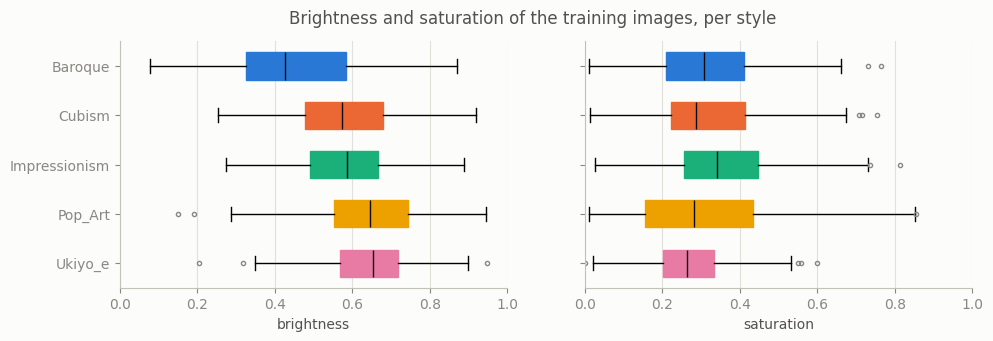

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for ax, feature in zip(axes, ("brightness", "saturation")):
    groups = [train_colour.loc[train_colour["label"] == c, feature] for c in classes]
    box = ax.boxplot(groups, vert=False, patch_artist=True, widths=0.55,
                     medianprops={"color": "#0b0b0b"}, flierprops={"markersize": 3, "markeredgecolor": "#898781"})
    for patch, c in zip(box["boxes"], classes):
        patch.set_facecolor(CLASS_COLORS[c])
        patch.set_edgecolor(CLASS_COLORS[c])
    ax.set_yticks(range(1, len(classes) + 1), classes)
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.set_xlabel(feature)
    ax.grid(axis="y", visible=False)
axes[1].set_yticklabels([])
fig.suptitle("Brightness and saturation of the training images, per style")
save_figure(fig, "01_colour_per_style")
plt.show()

**What we see.** **Baroque** paintings are clearly darker: their mean brightness is 0.45, against
0.57 to 0.64 for the other styles (think of the dark backgrounds of Rembrandt). Apart from that,
the boxes overlap a lot, and saturation alone separates almost nothing (means from 0.27 to 0.35).

So two simple colour numbers are not enough to recognise a style. A model needs richer
information: colour histograms, textures, shapes. We will give this kind of hand-made information
to the classical models; the neural networks must find it by themselves.

## 5. Near copies

**What we do.** WikiArt sometimes holds two scans of the same painting. We look for near copies
with a simple "fingerprint": each image is shrunk to 8 x 8 grey pixels and each pixel becomes 1 if
it is brighter than the image average, else 0 (64 bits, an *average hash*). Two images whose
fingerprints differ by 3 bits or less are candidates; we confirm them when their 32 x 32 grey
versions are very similar (correlation above 0.95).

In [12]:
def grey(size):
    return load_images(meta, size).float().mean(dim=1).flatten(1)  # (N, size * size)


g8 = grey(8)
bits = (g8 > g8.mean(dim=1, keepdim=True)).float()
hamming = bits @ (1 - bits).T + (1 - bits) @ bits.T            # differing bits for every pair
g32 = grey(32)
g32 = (g32 - g32.mean(dim=1, keepdim=True)) / g32.std(dim=1, keepdim=True)
corr = g32 @ g32.T / (g32.shape[1] - 1)

i, j = torch.triu_indices(len(meta), len(meta), offset=1)
candidate = hamming[i, j] <= 3
confirmed = candidate & (corr[i, j] > 0.95)
pairs = pd.DataFrame({"a": meta["id"].to_numpy()[i[confirmed]], "b": meta["id"].to_numpy()[j[confirmed]],
                      "split_a": meta["split"].to_numpy()[i[confirmed]],
                      "split_b": meta["split"].to_numpy()[j[confirmed]],
                      "corr": corr[i, j][confirmed].numpy().round(3)})
duplicates = {"candidate_pairs": int(candidate.sum()), "confirmed_pairs": len(pairs),
              "pairs_across_parts": int((pairs["split_a"] != pairs["split_b"]).sum()),
              "max_corr_candidates": round(corr[i, j][candidate].max().item(), 3),
              "max_corr_all_pairs": round(corr[i, j].max().item(), 3)}
print(duplicates)
pairs

{'candidate_pairs': 242, 'confirmed_pairs': 0, 'pairs_across_parts': 0, 'max_corr_candidates': 0.907, 'max_corr_all_pairs': 0.928}


,a,b,split_a,split_b,corr


**What we see.** 242 pairs of images have close fingerprints, but none of them is a real copy:
the highest correlation among these pairs is 0.91, and 0.93 over all the 1.1 million pairs, below
our 0.95 threshold. With this method we find **no near copy**, so no copy can carry information
from the training set to the test set.

## 6. A look at the paintings (local only)

In [13]:
if SHOW_ARTWORKS:
    fig, axes = plt.subplots(len(classes), 6, figsize=(12, 10.5))
    for row, c in enumerate(classes):
        idx = meta.index[(meta["label"] == c) & (meta["split"] == "train")][:6]
        for ax, k in zip(axes[row], idx):
            ax.imshow(load_images(meta.loc[[k]], 224)[0].permute(1, 2, 0))
            ax.set_xticks([]); ax.set_yticks([])
        axes[row, 0].set_ylabel(c)
    fig.savefig(PRIVATE_DIR / "01_samples.png", dpi=110, bbox_inches="tight")
    plt.show()
else:
    print("Paintings are not shown here (licence). Run with SHOW_ARTWORKS=1 to see them on your computer.")

Paintings are not shown here (licence). Run with SHOW_ARTWORKS=1 to see them on your computer.


In [14]:
save_results("01_data", {"n_images": len(meta), "classes": classes,
                         "split_counts": meta.groupby("split").size().to_dict(),
                         "known_painter_share": painters["share_known"].to_dict(),
                         "leakage": leak, "near_duplicates": duplicates})

WindowsPath('C:/Users/benca/OneDrive - Thelio/Documents/Perso/Albert School/Deep learning/neural-network-project/reports/results/01_data.json')

## What we learned

- **Balanced data**: 5 styles x 300 images, so the chance level is 20 %.
- **A fair split**: 1 061 / 219 / 220 images, stratified and grouped by painter (0 known painter in
  two parts, against 23 with a random split). The test set stays locked until notebook 05.
- **Not an easy task**: simple colour numbers only separate Baroque (darker) from the rest.
- **No near copies** found between images.
- **A limit**: 59 % of the images have an unknown painter, so the grouping cannot protect them.

**Next step** (notebook 02): a first neural network that looks only at the pixels.